# NEC-DINNs

This notebook runs DINN and NEC. Initial conditions are taken from each region's NPC `Range7_*.mat`, parameter bounds use NPC region-specific values, and the derived weekly incidence target is displayed as `infectious_case`.


## Setup

Keep `RUN_FULL_SWEEP = False` for inspection or smoke testing. Set it to `True` when you want to launch the full DINN/NEC run.

In [8]:
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd

import baseline_experiments as be
from baseline_experiments import (
    BaselineConfig,
    default_output_dir,
    discover_regions,
    run_all_baseline_table,
    run_real_experiment,
)

pd.set_option("display.max_columns", 120)
pd.set_option("display.width", 160)

TARGET_RENAME = {}
CITY_REGIONS = ["bello", "iquitos", "sanjuan"]
COUNTRY_REGIONS = ["cam", "phi", "vn"]


def rename_targets_for_display(df: pd.DataFrame) -> pd.DataFrame:
    out = df.copy()
    if "target" in out.columns:
        out["target"] = out["target"].replace(TARGET_RENAME)
    if "state" in out.columns:
        out["state"] = out["state"].replace(TARGET_RENAME)
    return out


In [9]:
REGIONS = discover_regions()
MODEL_TYPES = ("dinn", "nec")
EPOCHS = 20000

RESULTS_CSV = default_output_dir() / "baseline_results.csv"
PREDICTIONS_CSV = default_output_dir() / "baseline_predictions.csv"

if not REGIONS:
    raise RuntimeError(
        "No NPC data found under data_piml/npc. Place NPC data_cali.csv "
        "and data_proj.csv files under data_piml/npc/<region>/."
    )

print("regions:", REGIONS)
print("results:", RESULTS_CSV)
print("predictions:", PREDICTIONS_CSV)

regions: ['bello', 'cam', 'iquitos', 'phi', 'sanjuan', 'vn']
results: /Users/linhngo/Downloads/Work/PINNs/NEC/nec_dinns/outputs/baseline_results.csv
predictions: /Users/linhngo/Downloads/Work/PINNs/NEC/nec_dinns/outputs/baseline_predictions.csv


## Smoke Test

Short check on Iquitos DINN. Confirms `protocol='two_window'`, Range7 IC loaded, and per-region bounds active. After ep 500 the projection IC head is rewarmstarted from end-of-cal -- but at 2 epochs the smoke does not exercise that path.


In [10]:
RUN_SMOKE = True

if RUN_SMOKE:
    smoke_cfg = BaselineConfig(
        epochs=2,
        use_adaptive_phys=True,
        use_inc_soft=True,
        projection_ic_policy="A",
        protocol="two_window",
        range7_dir="/Users/linhngo/Downloads/Work/PINNs/NEC/nec_dinns",
        param_bounds_strategy="region",
    )
    smoke = run_real_experiment("iquitos", "dinn", smoke_cfg, verbose=True)
    smoke_keys = (
        "loss_itot", "loss_consistency", "loss_anchor", "loss_inc",
        "loss_residual_cal", "loss_residual_proj", "loss_ic_prior",
        "loss_itot_t0", "loss_horizon", "loss_continuity",
        "w_phys", "protocol",
    )
    print({k: smoke[k] for k in smoke_keys})
    smoke_metrics = rename_targets_for_display(smoke["metrics"])
    audit_cols = ["param_bounds_source", "param_bounds_path",
                  "cal_proj_gap_weeks", "w_inc_soft"]
    print("audit:", smoke_metrics.iloc[0][audit_cols].to_dict())
    display(
        smoke_metrics
        .query("split == 'calibration' and target in ['Itot', 'infectious_case', 'Hi']")
        [["region", "model", "split", "target",
          "mse_normalized", "Hi_status", "param_bounds_source"]]
    )


[iquitos] Range7 loaded from /Users/linhngo/Downloads/Work/PINNs/NEC/nec_dinns: lambda=[0.0050, 2.2190], theta_h=[0.0197, 0.8928], beta_m=[0.0462, 1.5831], mu_m=[0.0050, 0.8904]
[Iquitos] training DINN baseline
[iquitos] Range7 IC (cal Itot0=5.0, Hs0=4.64, He0=4.53, Mi0=1.51; max log1p=1.79)
ep     0 total=1.102e+01 itot=9.885e+00 phys=5.114e-07 a1=5.278e+00 a2=1.774e+00 w_phys=3.000e-01
{'loss_itot': 9.872478485107422, 'loss_consistency': 5.260676383972168, 'loss_anchor': 1.7686527967453003, 'loss_inc': 1.4277509450912476, 'loss_residual_cal': 2.554982643232506e-07, 'loss_residual_proj': 2.553852311848459e-07, 'loss_ic_prior': 4.5625336042576237e-07, 'loss_itot_t0': 2.5010683657455957e-07, 'loss_horizon': 0.0, 'loss_continuity': 2.0430716176633723e-05, 'w_phys': 0.3, 'protocol': 'two_window'}
audit: {'param_bounds_source': 'region', 'param_bounds_path': '/Users/linhngo/Downloads/Work/PINNs/NEC/nec_dinns', 'cal_proj_gap_weeks': 1.0, 'w_inc_soft': 0.2}


,region,model,split,target,mse_normalized,Hi_status,param_bounds_source
3,iquitos,dinn,calibration,Hi,NaN,not_observed,region
7,iquitos,dinn,calibration,Itot,0.342833,not_observed,region
8,iquitos,dinn,calibration,infectious_case,0.081132,not_observed,region


## Full DINN/NEC

Set `RUN_FULL_SWEEP = True` and run this cell to train all discovered regions for DINN and NEC. The output CSVs are written to `outputs/baseline_results.csv` and `outputs/baseline_predictions.csv`.

In [ ]:
RUN_FULL_SWEEP = True

full_cfg = BaselineConfig(
    epochs=EPOCHS,
    use_adaptive_phys=True,
    use_inc_soft=True,
    projection_ic_policy="A",
    protocol="two_window",
    range7_dir="/Users/linhngo/Downloads/Work/PINNs/NEC/nec_dinns",
    param_bounds_strategy="region",
)

if RUN_FULL_SWEEP:
    results = run_all_baseline_table(
        regions=REGIONS,
        model_types=MODEL_TYPES,
        config=full_cfg,
        output_csv=RESULTS_CSV,
        prediction_csv=PREDICTIONS_CSV,
        verbose=True,
    )
elif RESULTS_CSV.exists():
    results = pd.read_csv(RESULTS_CSV)
else:
    results = pd.DataFrame()
    print("No saved results yet. Set RUN_FULL_SWEEP = True to train.")

results = rename_targets_for_display(results)
results.head()


[bello] Range7 loaded from /Users/linhngo/Downloads/Work/PINNs/NEC/nec_dinns: lambda=[0.0050, 1.9444], theta_h=[0.0377, 1.0350], beta_m=[0.0609, 1.5863], mu_m=[0.0050, 0.9801]
[Bello] training DINN baseline
[bello] Range7 IC (cal Itot0=8.0, Hs0=4.55, He0=4.10, Mi0=1.62; max log1p=2.20)
ep     0 total=1.113e+01 itot=1.000e+01 phys=1.237e-06 a1=4.311e+00 a2=1.976e+00 w_phys=3.000e-01
ep   200 total=2.537e+00 itot=2.106e-01 phys=1.085e-06 a1=1.504e+00 a2=5.208e-03 w_phys=1.477e-01
ep   400 total=2.777e+00 itot=3.372e-02 phys=1.453e-06 a1=1.237e-01 a2=1.339e-05 w_phys=1.355e-01
[bello/dinn] ic_head_proj rewarmstarted from end-of-cal at ep 500
ep   600 total=1.163e-01 itot=3.188e-02 phys=2.542e-06 a1=7.563e-02 a2=3.324e-05 w_phys=1.227e-01
ep   800 total=1.119e-01 itot=2.979e-02 phys=2.509e-06 a1=8.085e-02 a2=5.935e-05 w_phys=1.081e-01
ep  1000 total=1.070e-01 itot=2.851e-02 phys=2.495e-06 a1=5.447e-02 a2=1.413e-05 w_phys=1.000e-01
ep  1200 total=1.024e-01 itot=2.638e-02 phys=2.436e-06 a1=5

## Score Tables

`Itot` is the primary NPC-comparable target. `infectious_case` is computed from cumulative cases and reported separately. `Hi` is tracked as not observed and excluded from score aggregation by design.


In [ ]:
if results.empty:
    print("No result table loaded yet.")
else:
    score_cols = ["region", "model", "mse_normalized", "train_seconds"]
    display(results[score_cols].sort_values(["region", "model"]))


,region,model,mse_normalized,train_seconds
0,bello,dinn,0.690506,122.661799
1,bello,nec,0.906537,96.276691
2,cam,dinn,0.130166,117.369008
3,cam,nec,0.141093,94.971578
4,iquitos,dinn,0.212633,118.544129
5,iquitos,nec,0.205421,96.386675
6,phi,dinn,0.607119,119.212988
7,phi,nec,0.597671,92.669412
8,sanjuan,dinn,0.826863,117.204623
9,sanjuan,nec,0.861788,93.778804


## Metric Plots

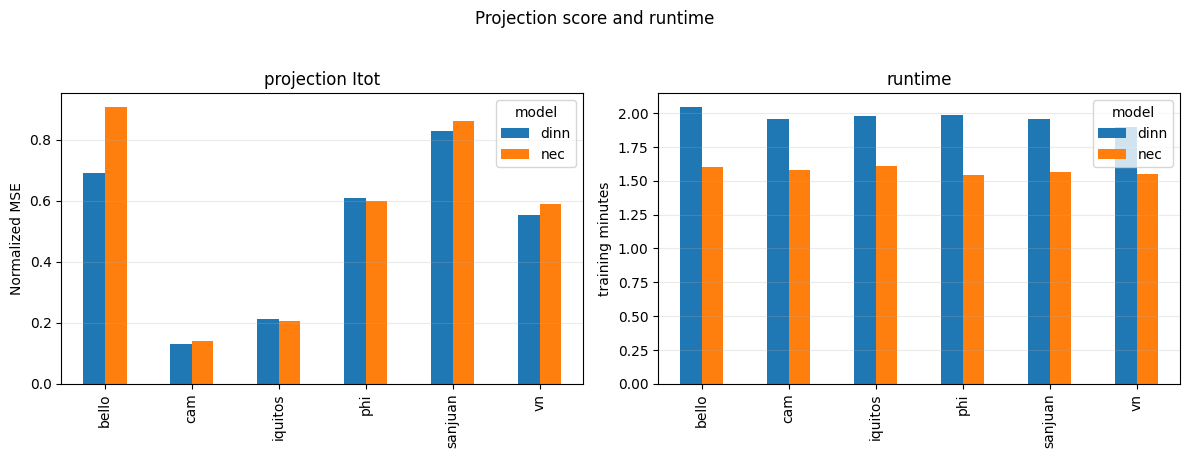

In [ ]:
if results.empty:
    print("No result table loaded yet.")
else:
    runtime_df = results.drop_duplicates(["region", "model"]).copy()

    fig, axes = plt.subplots(1, 2, figsize=(12, 4.4), sharey=False)
    score_pivot = results.pivot_table(index="region", columns="model", values="mse_normalized", aggfunc="mean")
    score_pivot = score_pivot.reindex(REGIONS)
    score_pivot.plot(kind="bar", ax=axes[0])
    axes[0].set_title("projection Itot")
    axes[0].set_ylabel("Normalized MSE")
    axes[0].set_xlabel("")
    axes[0].grid(axis="y", alpha=0.25)

    runtime_pivot = runtime_df.pivot_table(index="region", columns="model", values="train_seconds", aggfunc="mean")
    runtime_pivot = runtime_pivot.reindex(REGIONS)
    runtime_pivot.plot(kind="bar", ax=axes[1])
    axes[1].set_title("runtime")
    axes[1].set_ylabel("training seconds")
    axes[1].set_xlabel("")
    axes[1].grid(axis="y", alpha=0.25)

    fig.suptitle("Projection score and runtime", y=1.03)
    fig.tight_layout()


## Prediction Curves

Prediction curves show Ground Truth, DINN, and NEC together. Figures are separated by outbreak split and by region group: cities (`Bello`, `Iquitos`, `San Juan`) and countries (`Cambodia`, `Philippines`, `Vietnam`). `infectious_case` is the nonnegative weekly difference of cumulative cases.


wrote /Users/linhngo/Downloads/Work/PINNs/NEC/nec_dinns/outputs/prediction_group_plots/calibration_cities_dinn_nec.png
wrote /Users/linhngo/Downloads/Work/PINNs/NEC/nec_dinns/outputs/prediction_group_plots/calibration_countries_dinn_nec.png
wrote /Users/linhngo/Downloads/Work/PINNs/NEC/nec_dinns/outputs/prediction_group_plots/projection_cities_dinn_nec.png
wrote /Users/linhngo/Downloads/Work/PINNs/NEC/nec_dinns/outputs/prediction_group_plots/projection_countries_dinn_nec.png


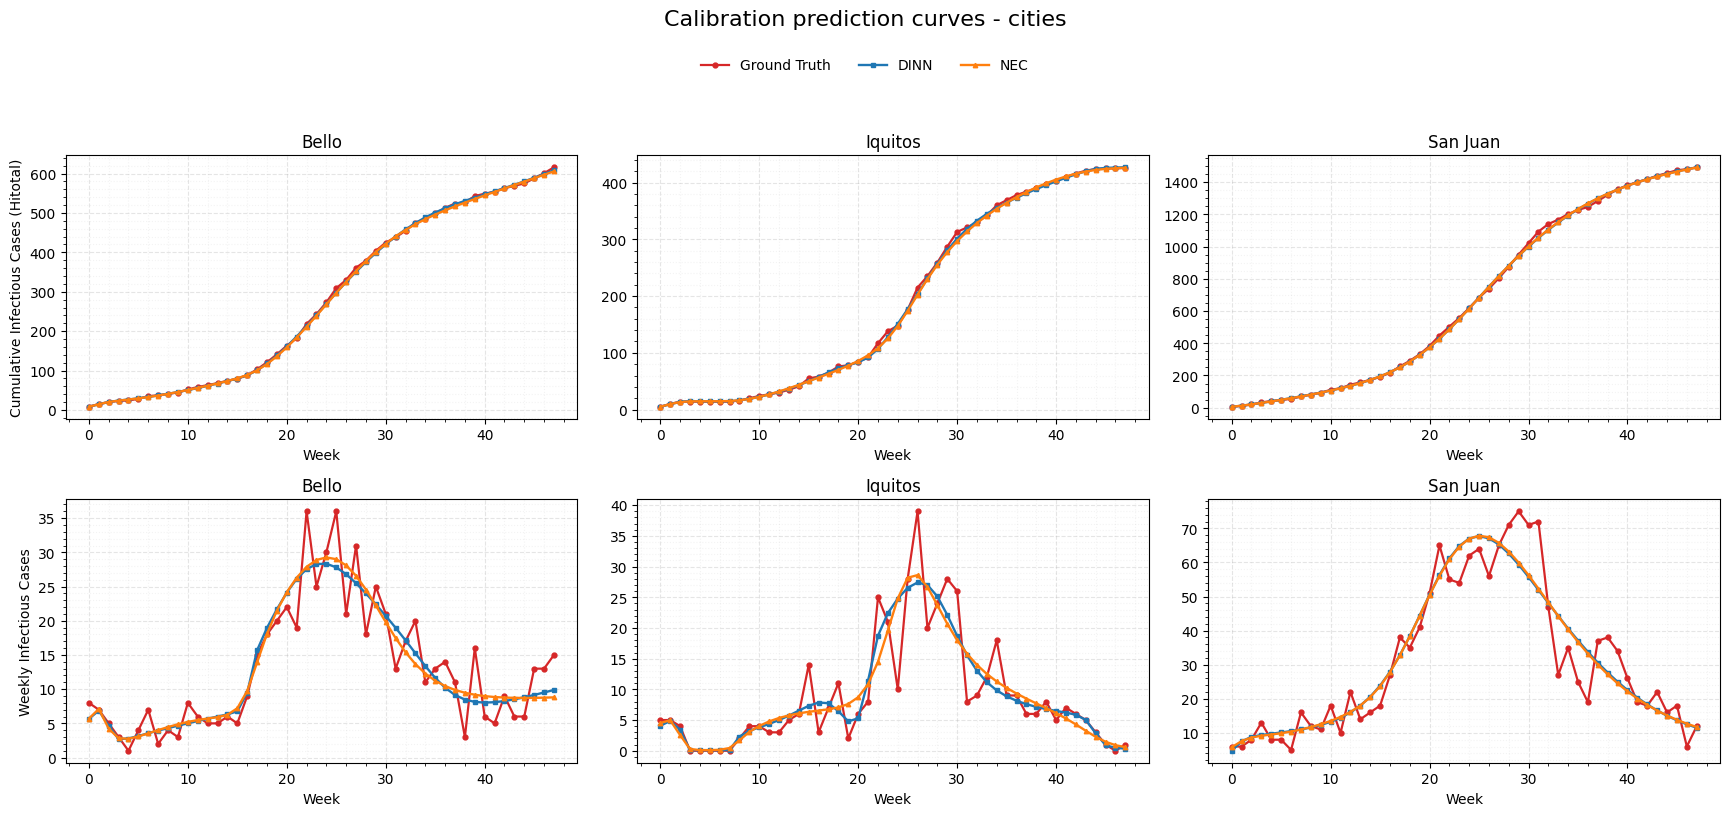

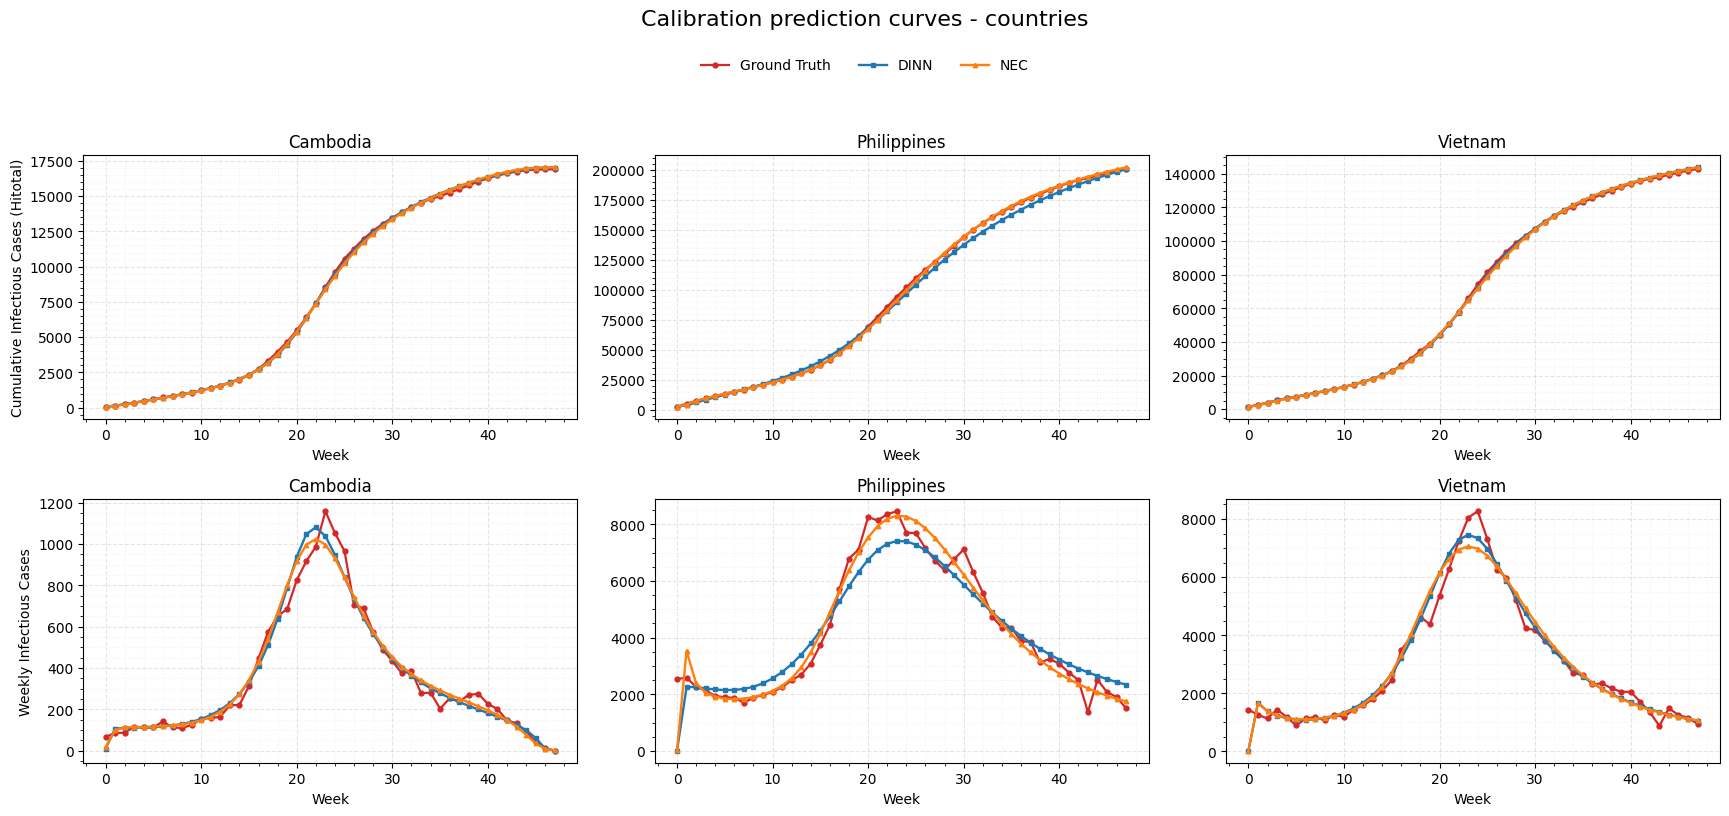

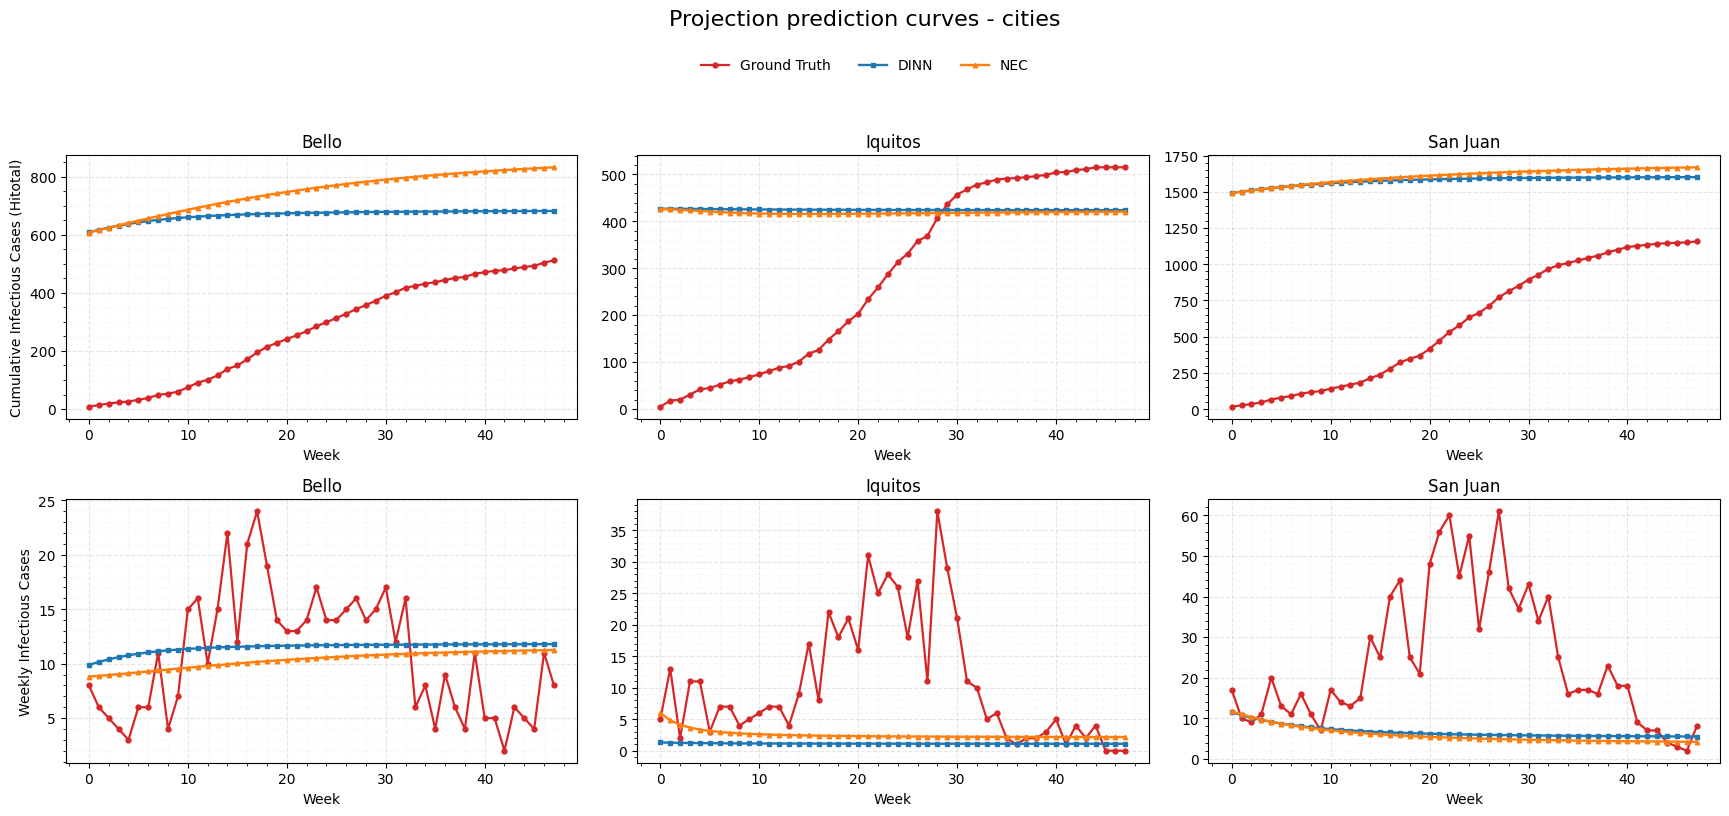

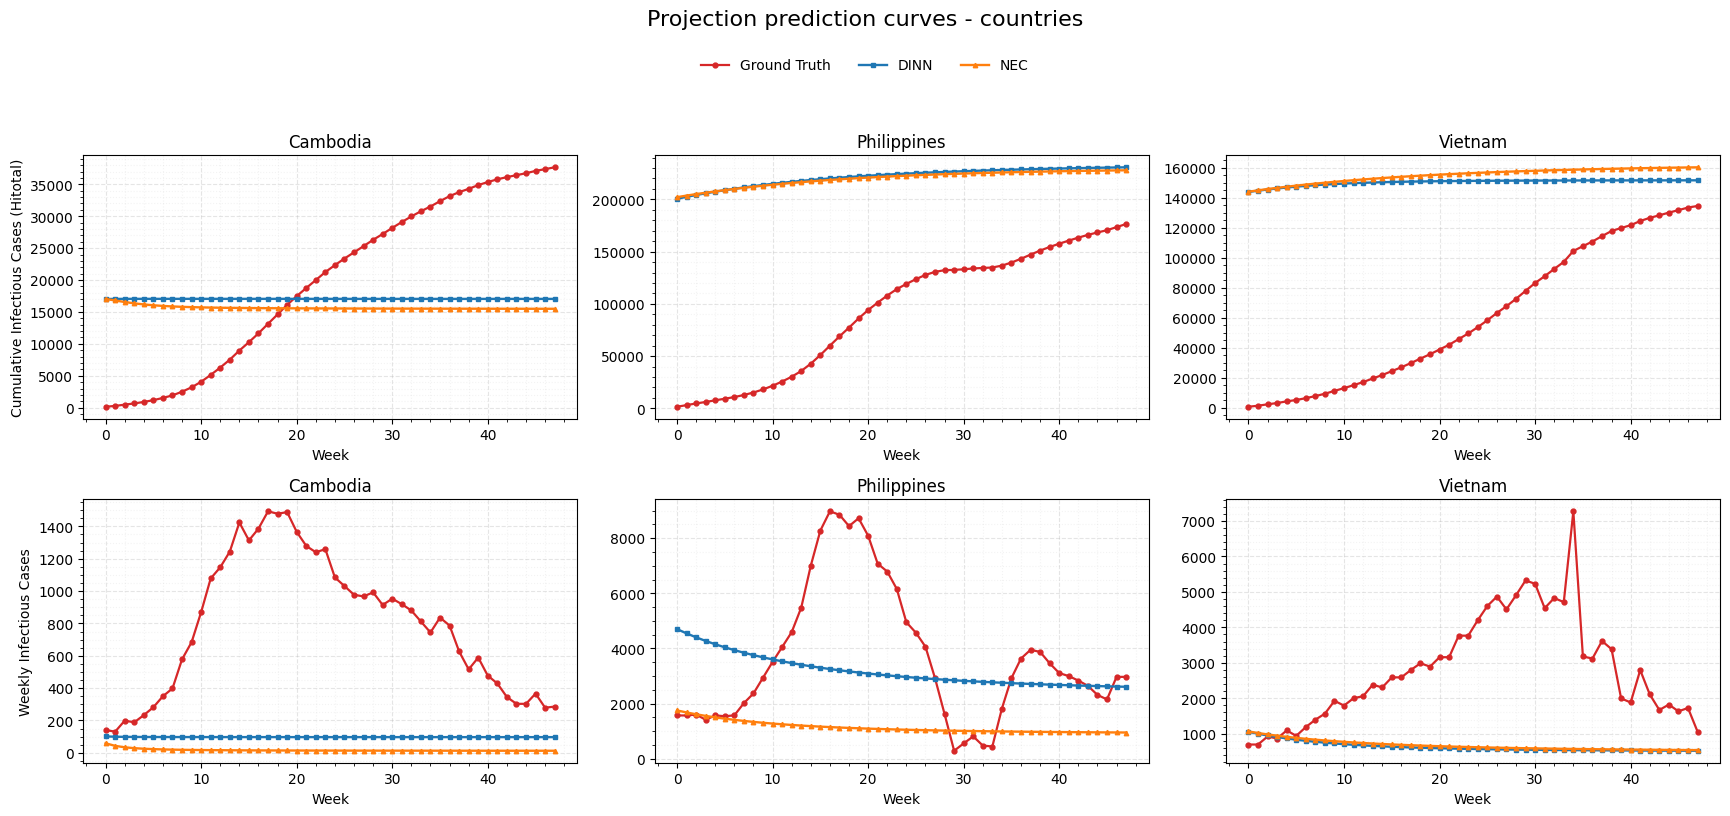

In [ ]:
if not PREDICTIONS_CSV.exists():
    print(f"No prediction CSV found at {PREDICTIONS_CSV}.")
else:
    preds = rename_targets_for_display(pd.read_csv(PREDICTIONS_CSV))
    group_plot_dir = default_output_dir() / "prediction_group_plots"
    group_plot_dir.mkdir(parents=True, exist_ok=True)

    target_order = ["Itot", "infectious_case"]
    target_titles = {
        "Itot": "Cumulative Infectious Cases (Hitotal)",
        "infectious_case": "Weekly Infectious Cases",
    }
    model_styles = {
        "dinn": {"label": "DINN", "color": "C0", "marker": "s"},
        "nec": {"label": "NEC", "color": "C1", "marker": "^"},
    }
    region_groups = [
        ("cities", [r for r in CITY_REGIONS if r in REGIONS]),
        ("countries", [r for r in COUNTRY_REGIONS if r in REGIONS]),
    ]
    split_order = ["calibration", "projection"]

    for split in split_order:
        for group_name, group_regions in region_groups:
            if not group_regions:
                continue
            fig, axes = plt.subplots(
                len(target_order),
                len(group_regions),
                figsize=(5.8 * len(group_regions), 8.2),
                sharex=False,
                sharey=False,
            )
            if len(group_regions) == 1:
                axes = axes.reshape(len(target_order), 1)

            for row_idx, target in enumerate(target_order):
                for col_idx, region in enumerate(group_regions):
                    ax = axes[row_idx, col_idx]
                    obs = preds[
                        preds["region"].eq(region)
                        & preds["split"].eq(split)
                        & preds["target"].eq(target)
                    ].copy()
                    if obs.empty:
                        ax.axis("off")
                        continue

                    label = obs["region_label"].iloc[0]
                    truth = obs.sort_values(["t", "model"]).drop_duplicates("t").sort_values("t")
                    ax.plot(
                        truth["t"],
                        truth["observed"],
                        color="C3",
                        marker="o",
                        markersize=3.5,
                        lw=1.6,
                        label="Ground Truth",
                    )

                    for model in MODEL_TYPES:
                        sub = obs[obs["model"].eq(model)].sort_values("t")
                        if sub.empty:
                            continue
                        style = model_styles.get(model, {"label": model.upper(), "color": None, "marker": None})
                        ax.plot(
                            sub["t"],
                            sub["predicted"],
                            color=style["color"],
                            marker=style["marker"],
                            markersize=3.2,
                            lw=1.7,
                            label=style["label"],
                        )

                    ax.set_title(label)
                    ax.set_xlabel("Week")
                    if col_idx == 0:
                        ax.set_ylabel(target_titles[target])
                    ax.minorticks_on()
                    ax.grid(which="major", linestyle="--", alpha=0.32)
                    ax.grid(which="minor", linestyle=":", alpha=0.14)

            handles, labels = axes[0, 0].get_legend_handles_labels()
            fig.suptitle(f"{split.title()} prediction curves - {group_name}", y=0.99, fontsize=16)
            fig.legend(
                handles,
                labels,
                loc="upper center",
                bbox_to_anchor=(0.5, 0.945),
                ncol=3,
                frameon=False,
            )
            fig.tight_layout(rect=(0, 0, 1, 0.90))

            out_path = group_plot_dir / f"{split}_{group_name}_dinn_nec.png"
            fig.savefig(out_path, dpi=180, bbox_inches="tight")
            print(f"wrote {out_path}")
